#Pyspark Install + Imports

In [ ]:
!pip -q install pyspark pandas matplotlib statsmodels scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

from pyspark.ml.classification import LogisticRegression
from pyspark.ml.regression import GBTRegressor

from pyspark.ml.evaluation import (
    BinaryClassificationEvaluator,
    MulticlassClassificationEvaluator,
    RegressionEvaluator
)

#Initialize Spark Session

In [ ]:
spark = (SparkSession.builder
         .appName("Checkin_Predictive_Analysis_Full")
         .getOrCreate())
spark.sparkContext.setLogLevel("WARN")
print("Spark:", spark.version)

Spark: 4.0.1


#Drive Mount

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#Input Path

In [ ]:
PATH = "/content/drive/MyDrive/CourseWork/CSV_Files/Cleaned_Output/Cleaned_checkin_daily_features.csv"
print("PATH =", PATH)

PATH = /content/drive/MyDrive/CourseWork/CSV_Files/Cleaned_Output/Cleaned_checkin_daily_features.csv


#Loading Dataset + Type Casting

In [ ]:
df_C1 = spark.read.csv(PATH, header=True, inferSchema=True)

cast_map = {
    "checkin_date": "date",
    "checkins": "double",
    "day_of_week": "int",
    "month": "int",
    "is_weekend": "int",
    "lag_1": "double",
    "lag_7": "double",
    "rolling_mean_7": "double",
}
df_C2 = df_C1
for c, t in cast_map.items():
    if c in df_C2.columns:
        df_C2 = df_C2.withColumn(c, F.col(c).cast(t))

df_C2 = df_C2.orderBy("checkin_date").cache()
print("Rows:", df_C2.count())
df_C2.show(5, truncate=False)

Rows: 4389
+------------+--------+---------------+-----------+-----+----+----------+-----+-----+--------------+------------+
|checkin_date|checkins|checkins_7d_avg|day_of_week|month|year|is_weekend|lag_1|lag_7|rolling_mean_7|high_traffic|
+------------+--------+---------------+-----------+-----+----+----------+-----+-----+--------------+------------+
|2009-12-30  |1.0     |1.0            |4          |12   |2009|0         |NULL |NULL |1.0           |0           |
|2009-12-31  |1.0     |1.0            |5          |12   |2009|0         |1.0  |NULL |1.0           |0           |
|2010-01-16  |100.0   |34.0           |7          |1    |2010|1         |1.0  |NULL |34.0          |0           |
|2010-01-17  |135.0   |59.25          |1          |1    |2010|1         |100.0|NULL |59.25         |0           |
|2010-01-18  |69.0    |61.2           |2          |1    |2010|0         |135.0|NULL |61.2          |0           |
+------------+--------+---------------+-----------+-----+----+----------+----

#Modeling Setup

In [ ]:
feature_cols = ["day_of_week", "month", "is_weekend", "lag_1", "lag_7", "rolling_mean_7"]
needed_cols = ["checkin_date", "checkins"] + feature_cols

df_C3 = (df_C2.select(*needed_cols)
         .dropna(subset=needed_cols)
         .orderBy("checkin_date")
         .cache())

print("Model rows after dropna:", df_C3.count())
df_C3.show(5, truncate=False)

Model rows after dropna: 4382
+------------+--------+-----------+-----+----------+-----+-----+--------------+
|checkin_date|checkins|day_of_week|month|is_weekend|lag_1|lag_7|rolling_mean_7|
+------------+--------+-----------+-----+----------+-----+-----+--------------+
|2010-01-21  |81.0    |5          |1    |0         |60.0 |1.0  |72.0          |
|2010-01-22  |73.0    |6          |1    |0         |81.0 |1.0  |82.29         |
|2010-01-23  |151.0   |7          |1    |1         |73.0 |100.0|89.57         |
|2010-01-24  |155.0   |1          |1    |1         |151.0|135.0|92.43         |
|2010-01-25  |70.0    |2          |1    |0         |155.0|69.0 |92.57         |
+------------+--------+-----------+-----+----------+-----+-----+--------------+
only showing top 5 rows


#Time-based Train/Test Split

In [ ]:
df_C4 = df_C3.withColumn("date_num", F.col("checkin_date").cast("timestamp").cast("long"))
cutoff = df_C4.approxQuantile("date_num", [0.8], 0.001)[0]

df_train = df_C4.filter(F.col("date_num") <= F.lit(cutoff)).drop("date_num").cache()
df_test  = df_C4.filter(F.col("date_num") >  F.lit(cutoff)).drop("date_num").cache()

print("Train:", df_train.count(), "| Test:", df_test.count())
df_train.select(F.min("checkin_date").alias("train_min"), F.max("checkin_date").alias("train_max")).show()
df_test.select(F.min("checkin_date").alias("test_min"), F.max("checkin_date").alias("test_max")).show()

Train: 3505 | Test: 877
+----------+----------+
| train_min| train_max|
+----------+----------+
|2010-01-21|2019-08-26|
+----------+----------+

+----------+----------+
|  test_min|  test_max|
+----------+----------+
|2019-08-27|2022-01-19|
+----------+----------+



#Predictive Analysis

##Classification : Logistic Regression

###Target: High-Traffic Day

In [ ]:
from pyspark.sql import functions as F, Row
from pyspark.ml import Pipeline
from pyspark.ml.feature import OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

#Label (TRAIN-only threshold to avoid leakage)
p75_train = df_train.approxQuantile("checkins", [0.75], 0.001)[0]
train_clf = df_train.withColumn("label", (F.col("checkins") > F.lit(p75_train)).cast("int"))
test_clf  = df_test.withColumn("label",  (F.col("checkins") > F.lit(p75_train)).cast("int"))

numeric_features = ["month", "is_weekend", "lag_1", "lag_7", "rolling_mean_7"]

ohe = OneHotEncoder(
    inputCols=["day_of_week"],
    outputCols=["day_of_week_ohe"],
    dropLast=True
)

#Assemble: numeric + ohe vector
assembler = VectorAssembler(
    inputCols=numeric_features + ["day_of_week_ohe"],
    outputCol="features_raw",
    handleInvalid="skip"
)

scaler = StandardScaler(inputCol="features_raw", outputCol="features", withMean=False, withStd=True)

lr = LogisticRegression(featuresCol="features", labelCol="label")

clf_pipe = Pipeline(stages=[ohe, assembler, scaler, lr])

#Hyperparameter Grid
clf_grid = (ParamGridBuilder()
    .addGrid(lr.regParam, [0.0, 0.06, 0.1])
    .addGrid(lr.elasticNetParam, [0.0, 0.9, 1.0])
    .addGrid(lr.maxIter, [100, 300])
    .build()
)

#Cross Validation (best by ROC-AUC)
auc_eval = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

clf_cv = CrossValidator(
    estimator=clf_pipe,
    estimatorParamMaps=clf_grid,
    evaluator=auc_eval,
    numFolds=3,
    parallelism=2,
    seed=12
)

# Train + Predict
clf_cv_model = clf_cv.fit(train_clf)
clf_pred = clf_cv_model.transform(test_clf).cache()
_ = clf_pred.count()

# Metrics
roc_auc = auc_eval.evaluate(clf_pred)
acc = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction",
                                        metricName="accuracy").evaluate(clf_pred)
f1  = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction",
                                        metricName="f1").evaluate(clf_pred)

best_lr = clf_cv_model.bestModel.stages[-1]
best_params = f"regParam={best_lr.getRegParam()}, elasticNet={best_lr.getElasticNetParam()}, maxIter={best_lr.getMaxIter()}"

print("CLASSIFICATION RESULTS (with day_of_week OHE)")
print(f"Target: High_Traffic (1 if checkins > train_p75={p75_train})")
print(f"Best params → {best_params}")
print(f"Metrics → ROC-AUC={roc_auc:.3f}, Accuracy={acc:.3f}, F1={f1:.3f}")

#Final Output Table
df_clf_summary = spark.createDataFrame([Row(
    Model="LogisticRegression (CV) + OHE(day_of_week)",
    Task="Classification",
    Target=f"High_Traffic (1 if checkins > train_p75={p75_train})",
    Seed=12,
    Best_Params=best_params,
    ROC_AUC=float(roc_auc),
    Accuracy=float(acc),
    F1=float(f1)
)])
df_clf_summary.show(truncate=False)


CLASSIFICATION RESULTS (with day_of_week OHE)
Target: High_Traffic (1 if checkins > train_p75=4319.0)
Best params → regParam=0.0, elasticNet=0.0, maxIter=100
Metrics → ROC-AUC=0.988, Accuracy=0.992, F1=0.989
+------------------------------------------+--------------+-----------------------------------------------+----+-----------------------------------------+------------------+-----------------+------------------+
|Model                                     |Task          |Target                                         |Seed|Best_Params                              |ROC_AUC           |Accuracy         |F1                |
+------------------------------------------+--------------+-----------------------------------------------+----+-----------------------------------------+------------------+-----------------+------------------+
|LogisticRegression (CV) + OHE(day_of_week)|Classification|High_Traffic (1 if checkins > train_p75=4319.0)|12  |regParam=0.0, elasticNet=0.0, maxIter=100|0.987

##Classification Model Evaluation

###1. ROC Curve

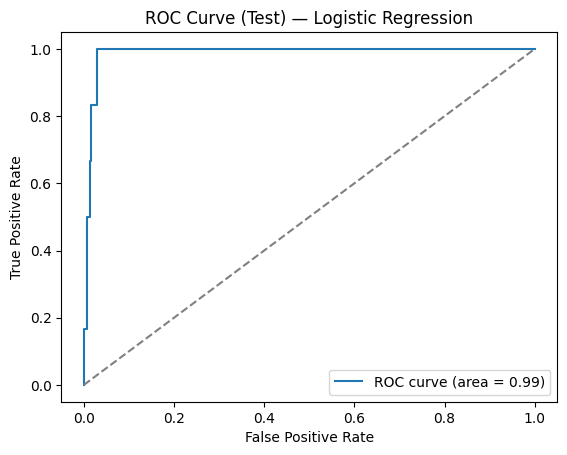

In [ ]:
# CHART: ROC Curve (Classification)

import matplotlib.pyplot as plt
from pyspark.sql import functions as F
from pyspark.ml.functions import vector_to_array
from pyspark.mllib.evaluation import BinaryClassificationMetrics
import pandas as pd # Import pandas for DataFrame creation
from sklearn.metrics import roc_curve, auc # Import roc_curve and auc from scikit-learn

scored = (
    clf_pred
    .select(
        F.col("label").cast("double").alias("label"),
        vector_to_array("probability")[1].alias("p1")  # P(class=1)
    )
    .dropna()
)

# Convert to Pandas DataFrame for scikit-learn
pd_scored = scored.toPandas()

# Calculate ROC curve using scikit-learn
fpr, tpr, thresholds = roc_curve(pd_scored["label"], pd_scored["p1"])
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0,1], [0,1], linestyle="--", color='grey')
plt.title("ROC Curve (Test) — Logistic Regression")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.show()

###2. Confusion Metrix

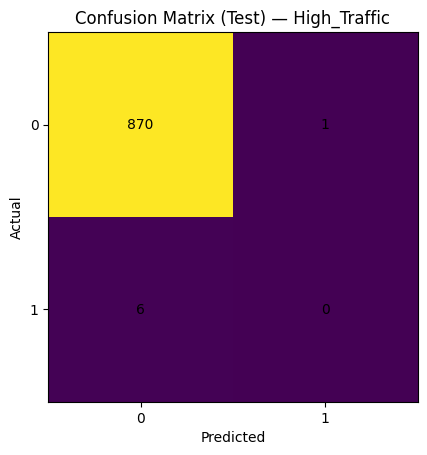

In [ ]:
# CHART: Confusion Matrix (Classification)

import numpy as np
import matplotlib.pyplot as plt

cm_pd = (clf_pred
    .groupBy("label", "prediction")
    .count()
    .toPandas()
)

mat = np.zeros((2,2), dtype=int)
for _, r in cm_pd.iterrows():
    mat[int(r["label"]), int(r["prediction"])] = int(r["count"])

plt.figure()
plt.imshow(mat)
plt.title("Confusion Matrix (Test) — High_Traffic")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0,1], ["0","1"])
plt.yticks([0,1], ["0","1"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, str(mat[i,j]), ha="center", va="center")
plt.show()


###3. Precision-Recall Curve

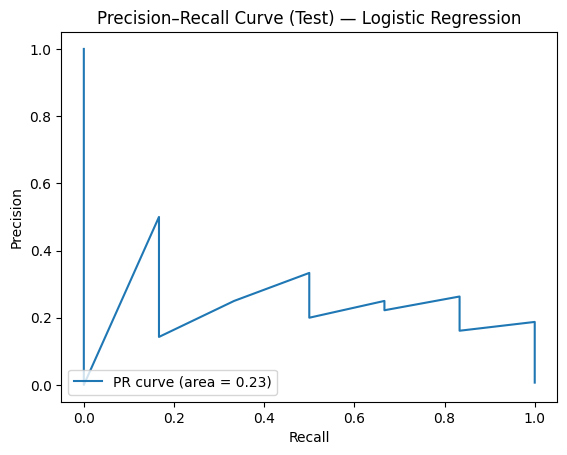

In [ ]:
# CHART: Precision–Recall Curve (Classification)

import matplotlib.pyplot as plt
from pyspark.sql import functions as F
from pyspark.ml.functions import vector_to_array
import pandas as pd # Import pandas for DataFrame creation
from sklearn.metrics import precision_recall_curve, auc

# Ensure `scored` DataFrame is available (same as for ROC curve)
scored = (
    clf_pred
    .select(
        F.col("label").cast("double").alias("label"),
        vector_to_array("probability")[1].alias("p1")  # P(class=1)
    )
    .dropna()
)

# Convert to Pandas DataFrame for scikit-learn
pd_scored_pr = scored.toPandas()

# Calculate Precision-Recall curve using scikit-learn
precision, recall, _ = precision_recall_curve(pd_scored_pr["label"], pd_scored_pr["p1"])
pr_auc = auc(recall, precision)

plt.figure()
plt.plot(recall, precision, label=f'PR curve (area = {pr_auc:.2f})')
plt.title("Precision–Recall Curve (Test) — Logistic Regression")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(loc="lower left")
plt.show()

##Regression : GBTRegressor

###Target: y = log1p(checkins)

In [ ]:
from pyspark.sql import functions as F, Row
from pyspark import StorageLevel
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

#Target transform
train_reg = df_train.withColumn("y", F.log1p(F.col("checkins")))
test_reg  = df_test.withColumn("y",  F.log1p(F.col("checkins")))

#Persist to prevent recomputation during CV
train_reg = train_reg.persist(StorageLevel.MEMORY_AND_DISK)
test_reg  = test_reg.persist(StorageLevel.MEMORY_AND_DISK)
_ = train_reg.count(); _ = test_reg.count()

#Pipeline
assembler = VectorAssembler(inputCols=feature_cols, outputCol="features", handleInvalid="skip")

gbt = GBTRegressor(featuresCol="features", labelCol="y", seed=10)

reg_pipe = Pipeline(stages=[assembler, gbt])

#Hyperparameter Grid
reg_grid = (ParamGridBuilder()
    .addGrid(gbt.maxDepth, [3, 5])
    .addGrid(gbt.maxIter, [30])
    .addGrid(gbt.stepSize, [0.1])
    .build()
)

#Cross Validation (optimize RMSE)
rmse_eval = RegressionEvaluator(labelCol="y", predictionCol="prediction", metricName="rmse")

reg_cv = CrossValidator(
    estimator=reg_pipe,
    estimatorParamMaps=reg_grid,
    evaluator=rmse_eval,
    numFolds=5,
    parallelism=2,
    seed=10
)


#Train + predict
reg_cv_model = reg_cv.fit(train_reg)
reg_pred = reg_cv_model.transform(test_reg).cache()
_ = reg_pred.count()

#Metrics
rmse = rmse_eval.evaluate(reg_pred)
mae  = RegressionEvaluator(labelCol="y", predictionCol="prediction", metricName="mae").evaluate(reg_pred)
r2   = RegressionEvaluator(labelCol="y", predictionCol="prediction", metricName="r2").evaluate(reg_pred)

#Back-transform for MAPE on raw scale
reg_pred2 = (reg_pred
    .withColumn("pred_checkins", F.expm1(F.col("prediction")))
    .withColumn("abs_pct_err",
                F.when(F.col("checkins") == 0, F.lit(None))
                 .otherwise(F.abs((F.col("checkins") - F.col("pred_checkins")) / F.col("checkins"))))
)

mape = reg_pred2.agg(F.mean("abs_pct_err").alias("mape")).collect()[0]["mape"]

#Best params
best_gbt = reg_cv_model.bestModel.stages[-1]
best_params = f"maxDepth={best_gbt.getMaxDepth()}, maxIter={best_gbt.getMaxIter()}, stepSize={best_gbt.getStepSize()}"

print("\nREGRESSION RESULTS (y = log1p(checkins))")
print(f"Best params → {best_params}")
print(f"Metrics → RMSE={rmse:.3f}, MAE={mae:.3f}, R2={r2:.3f}, MAPE={mape:.3f}" if mape is not None else
      f"Metrics → RMSE={rmse:.3f}, MAE={mae:.3f}, R2={r2:.3f}, MAPE=N/A")

#Final Output Table
df_reg_summary = spark.createDataFrame([Row(
    Model="GBTRegressor (CV)",
    Task="Regression",
    Target="y = log1p(checkins)",
    Seed=10,
    Best_Params=best_params,
    RMSE=float(rmse),
    MAE=float(mae),
    R2=float(r2),
    MAPE=float(mape) if mape is not None else None
)])
df_reg_summary.show(truncate=False)



REGRESSION RESULTS (y = log1p(checkins))
Best params → maxDepth=5, maxIter=30, stepSize=0.1
Metrics → RMSE=0.287, MAE=0.180, R2=0.707, MAPE=0.180
+-----------------+----------+-------------------+----+------------------------------------+------------------+-------------------+------------------+-------------------+
|Model            |Task      |Target             |Seed|Best_Params                         |RMSE              |MAE                |R2                |MAPE               |
+-----------------+----------+-------------------+----+------------------------------------+------------------+-------------------+------------------+-------------------+
|GBTRegressor (CV)|Regression|y = log1p(checkins)|10  |maxDepth=5, maxIter=30, stepSize=0.1|0.2874897089776448|0.17992902606552813|0.7074751382087197|0.17961743630293256|
+-----------------+----------+-------------------+----+------------------------------------+------------------+-------------------+------------------+-------------------

##Regression Model Evaluation

###1. Actual vs Predicted (log Scale)

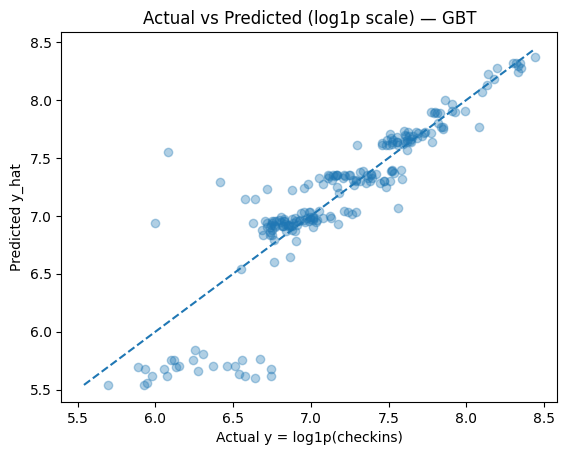

In [ ]:
# CHART: Actual vs Predicted (log scale)

import matplotlib.pyplot as plt

pdf_reg = (reg_pred2
    .select("y", "prediction")
    .dropna()
    .sample(False, 0.25, seed=12)
    .toPandas()
)

plt.figure()
plt.scatter(pdf_reg["y"], pdf_reg["prediction"], alpha=0.35)
mn = min(pdf_reg["y"].min(), pdf_reg["prediction"].min())
mx = max(pdf_reg["y"].max(), pdf_reg["prediction"].max())
plt.plot([mn, mx], [mn, mx], linestyle="--")
plt.title("Actual vs Predicted (log1p scale) — GBT")
plt.xlabel("Actual y = log1p(checkins)")
plt.ylabel("Predicted y_hat")
plt.show()


###2. Residuals vs Predicted (log Scale)

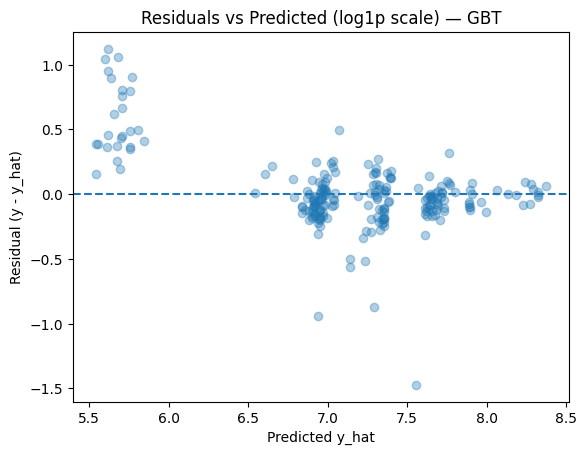

In [ ]:
# CHART: Residuals vs Predicted (log scale)

import matplotlib.pyplot as plt

pdf_reg = (reg_pred2
    .select("y", "prediction")
    .dropna()
    .sample(False, 0.25, seed=12)
    .toPandas()
)

resid = pdf_reg["y"] - pdf_reg["prediction"]

plt.figure()
plt.scatter(pdf_reg["prediction"], resid, alpha=0.35)
plt.axhline(0, linestyle="--")
plt.title("Residuals vs Predicted (log1p scale) — GBT")
plt.xlabel("Predicted y_hat")
plt.ylabel("Residual (y - y_hat)")
plt.show()


###3. Actual vs Predicted (original scale)

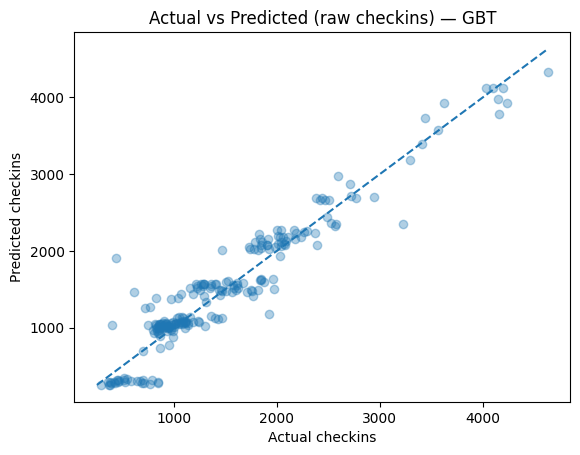

In [ ]:
# CHART: Actual vs Predicted (original scale)

import matplotlib.pyplot as plt

pdf_raw = (reg_pred2
    .select("checkins", "pred_checkins")
    .dropna()
    .sample(False, 0.25, seed=12)
    .toPandas()
)

plt.figure()
plt.scatter(pdf_raw["checkins"], pdf_raw["pred_checkins"], alpha=0.35)
mn = min(pdf_raw["checkins"].min(), pdf_raw["pred_checkins"].min())
mx = max(pdf_raw["checkins"].max(), pdf_raw["pred_checkins"].max())
plt.plot([mn, mx], [mn, mx], linestyle="--")
plt.title("Actual vs Predicted (raw checkins) — GBT")
plt.xlabel("Actual checkins")
plt.ylabel("Predicted checkins")
plt.show()
